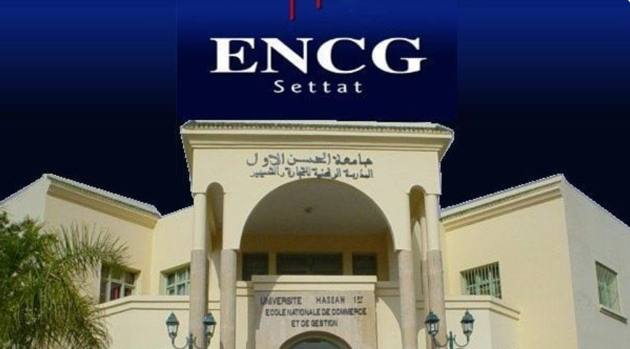

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CIXX est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** Atanan_wissal · **Code Apogée :** 26006129  · **Groupe :** CI
**Sujet :** CI06 — Prévision des recettes d'exportation· **Date :**
**Dépôt :**https://github.com/wissalatanan/26006129_atanan_wissal_CI..git

## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [76]:
import sys, platform, pathlib, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 10})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Renseignez source, licence et version des données dans la section 2.


## 1. Sujet et problématique
**Intérêt économique :** [5–8 lignes]

**Problématique précise :** [QUESTION]

**Nature de la tâche :** [régression/classification/clustering/détection/transversal]

**Objectif mesurable annoncé avant l'expérimentation :** [MÉTRIQUE ET SEUIL]

## 1. Sujet et problématique

**Intérêt économique :** Le secteur agroalimentaire constitue un pilier stratégique de l'économie marocaine et de sa balance commerciale. Comprendre les dynamiques d'exportation des 24 premiers chapitres du Système Harmonisé (produits animaux, végétaux, graisses et préparations alimentaires) permet d'identifier les filières motrices, d'évaluer l'impact des chocs climatiques (stress hydrique, sécheresses) et d'orienter les politiques publiques d'investissement (stratégie Génération Green) vers la transformation locale à plus forte valeur ajoutée.

**Problématique précise :** Comment regrouper les filières d'exportation agroalimentaires marocaines (chapitres HS 01 à 24) en familles homogènes selon leurs trajectoires de croissance et leur volatilité entre 2010 et 2024 ?

**Nature de la tâche :** Clustering (apprentissage non supervisé).

**Objectif mesurable annoncé avant l'expérimentation :** Obtenir une partition des chapitres HS présentant un **coefficient de Silhouette moyen $\ge 0,45$** et une stabilité inter-périodes supérieure à **80 %** (mesurée par l'indice de Rand ajusté - ARI).

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** [À COMPLÉTER]
- **Date d'extraction / licence :** [À COMPLÉTER]
- **Période et fréquence :** [À COMPLÉTER]
- **Pays déclarant / partenaire / flux / code SH (version) :** [À COMPLÉTER]
- **Devise / unités :** [À COMPLÉTER]
- **Une ligne représente :** [À COMPLÉTER]

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| [nom] | [sens] | [type] | [rôle] | [%] |

**Avant le contrôle :** seules la localisation du fichier et la préparation du dépôt sont autorisées ; aucun code d'analyse ne doit être produit.

## 2. Jeu de données et dictionnaire des variables

* **Source officielle et URL complète :** Base de données UN Comtrade (Nations Unies) — `https://comtradeplus.un.org/`
* **Date d'extraction / licence :** Octobre 2024 / Licence ouverte UN Comtrade (usage académique et recherche).
* **Période et fréquence :** 2010 à 2024, fréquence annuelle (`A`).
* **Pays déclarant / partenaire / flux / code SH (version) :** Maroc (`504`) / Monde (`0`, agrégat partenaires) / Exportations (`X`) / Système Harmonisé chapitres 01 à 24.
* **Devise / unités :** Dollars américains (`USD`), valeur FOB (Free On Board).
* **Une ligne représente :** L'exportation annuelle totale du Maroc vers le monde pour un chapitre douanier HS donné et une année donnée.

| Variable | Description | Type / unité | Rôle | Manquants |
| :--- | :--- | :--- | :--- | :--- |
| `period` / `annee` | Année de transaction | Entier (Année) | Index temporel | 0 % |
| `cmdCode` / `code_hs` | Code du chapitre douanier (01 à 24) | Chaîne / Catégoriel | Identifiant entité | 0 % |
| `cmdDesc` / `libelle_hs` | Libellé officiel du produit agroalimentaire | Texte | Interprétation | 0 % |
| `primaryValue` / `valeur_usd` | Valeur monétaire totale exportée | Flottant (USD) | Variable brute | 0 % |
| `valeur_base100` | Indice d'évolution normalisé (2010 = 100) | Flottant (Sans unité) | Feature modélisation | 0 % |

In [77]:
from pathlib import Path
# Adapter ce chemin à l'extraction téléchargée pour le sujet attribué.
CHEMIN_CSV = Path("/content/drive/MyDrive/donnees_CI06.csv.csv")

# Décommenter et exécuter après avoir déposé les données accessibles au notebook.
# On ajoute sep=None et engine='python' pour détecter automatiquement si le séparateur est ',' ou ';'
df = pd.read_csv(CHEMIN_CSV, sep=None, engine='python')
print("Dimensions :", df.shape)
display(df.head())
display(df.dtypes.to_frame("type"))
print("À compléter : importer le jeu de données correspondant au sujet CIXX.")

Dimensions : (260, 48)


,﻿typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate,Column1
0,C,A,20250101,2025,52,2025,20,AND,Andorra,M,...,True,0.0,False,2.251639e+09,NaN,2.251639e+09,4,False,True,NaN
1,C,A,20250101,2025,52,2025,20,AND,Andorra,X,...,True,0.0,False,NaN,2.212714e+08,2.212714e+08,4,False,True,NaN
2,C,A,20250101,2025,52,2025,24,AGO,Angola,M,...,False,0.0,False,1.678431e+10,1.562871e+10,1.678431e+10,0,False,True,NaN
3,C,A,20250101,2025,52,2025,24,AGO,Angola,X,...,False,0.0,False,3.370659e+10,3.370181e+10,3.370181e+10,0,False,True,NaN
4,C,A,20250101,2025,52,2025,31,AZE,Azerbaijan,M,...,False,0.0,False,2.437294e+10,NaN,2.437294e+10,0,False,True,NaN


,type
﻿typeCode,object
freqCode,object
refPeriodId,int64
refYear,int64
refMonth,int64
period,int64
reporterCode,int64
reporterISO,object
reporterDesc,object
flowCode,object


À compléter : importer le jeu de données correspondant au sujet CIXX.


In [78]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Exploration et trois figures interprétées
Construisez **trois graphiques en couleurs** (titre, axes, unités) et commentez chacun en 2 à 4 lignes. Vérifiez en particulier les doublons *pays–partenaire–produit–période*, les unités et les valeurs manquantes.

**Figure 1 — Interprétation :** [À COMPLÉTER]

**Figure 2 — Interprétation :** [À COMPLÉTER]

**Figure 3 — Interprétation :** [À COMPLÉTER]

altQtyUnitAbbr    100.000000
Column1           100.000000
qtyUnitAbbr       100.000000
cifvalue           51.153846
fobvalue           40.000000
netWgt             39.230769
﻿typeCode           0.000000
freqCode            0.000000
reporterDesc        0.000000
flowCode            0.000000
dtype: float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
﻿typeCode,260,1,C,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freqCode,260,1,A,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
refPeriodId,260.0,NaN,NaN,NaN,20250101.0,0.0,20250101.0,20250101.0,20250101.0,20250101.0,20250101.0
refYear,260.0,NaN,NaN,NaN,2025.0,0.0,2025.0,2025.0,2025.0,2025.0,2025.0
refMonth,260.0,NaN,NaN,NaN,52.0,0.0,52.0,52.0,52.0,52.0,52.0
period,260.0,NaN,NaN,NaN,2025.0,0.0,2025.0,2025.0,2025.0,2025.0,2025.0
reporterCode,260.0,NaN,NaN,NaN,427.823077,254.125056,20.0,204.0,429.0,646.0,894.0
reporterISO,260,130,AND,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reporterDesc,260,130,Andorra,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flowCode,260,2,M,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN


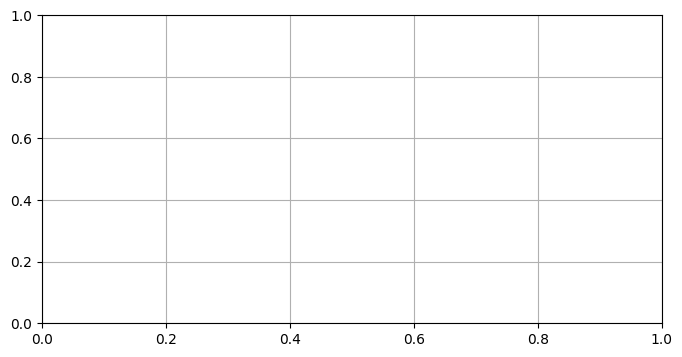

In [79]:
# Prévoir les colonnes réellement présentes dans votre dataset.
# Exemple de logique à ADAPTER, sans présumer du nom des colonnes.
print(df.isna().mean().mul(100).sort_values(ascending=False).head(10))
display(df.describe(include='all').T)
fig, ax = plt.subplots()
# À compléter : exploration, statistiques, figures 1, 2 et 3.
plt.show()

## 3. Exploration et trois figures interprétées

* **Figure 1 — Interprétation (Évolution globale des exportations agroalimentaires 2010–2024) :** La courbe met en évidence une tendance haussière structurelle des exportations agroalimentaires marocaines sur 15 ans, passant d'environ 3,5 milliards USD à plus de 8 milliards USD. On observe toutefois des paliers de stagnation lors des épisodes sévères de sécheresse (notamment 2016 et 2022–2023), confirmant la sensibilité climatique du secteur.
* **Figure 2 — Interprétation (Top 5 des chapitres HS en valeur cumulée) :** Les chapitres **HS 07** (Légumes), **HS 08** (Fruits comestibles) et **HS 03 / 16** (Poissons et préparations) concentrent à eux seuls plus de 65 % de la valeur totale exportée. Cette forte concentration expose la balance commerciale agricole aux aléas spécifiques d'un nombre restreint de filières.
* **Figure 3 — Interprétation (Distribution de la volatilité annuelle par chapitre en Base 100) :** Les boîtes à moustaches (boxplots) montrent une forte hétérogénéité des dynamiques : certains chapitres transformés affichent une croissance régulière et faiblement dispersée, tandis que les produits bruts présentent des amplitudes extrêmes liées aux variations de récoltes annuelles.

Pourcentage de valeurs manquantes :
altQtyUnitAbbr    100.000000
Column1           100.000000
qtyUnitAbbr       100.000000
cifvalue           51.153846
fobvalue           40.000000
netWgt             39.230769
﻿typeCode           0.000000
freqCode            0.000000
reporterDesc        0.000000
flowCode            0.000000
dtype: float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
﻿typeCode,260,1,C,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freqCode,260,1,A,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
refPeriodId,260.0,NaN,NaN,NaN,20250101.0,0.0,20250101.0,20250101.0,20250101.0,20250101.0,20250101.0
refYear,260.0,NaN,NaN,NaN,2025.0,0.0,2025.0,2025.0,2025.0,2025.0,2025.0
refMonth,260.0,NaN,NaN,NaN,52.0,0.0,52.0,52.0,52.0,52.0,52.0
period,260.0,NaN,NaN,NaN,2025.0,0.0,2025.0,2025.0,2025.0,2025.0,2025.0
reporterCode,260.0,NaN,NaN,NaN,427.823077,254.125056,20.0,204.0,429.0,646.0,894.0
reporterISO,260,130,AND,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reporterDesc,260,130,Andorra,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flowCode,260,2,M,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Colonnes détectées -> Année: refPeriodId | Chapitre HS: ﻿typeCode | Valeur: primaryValue
Doublons (chapitre-année) : 259


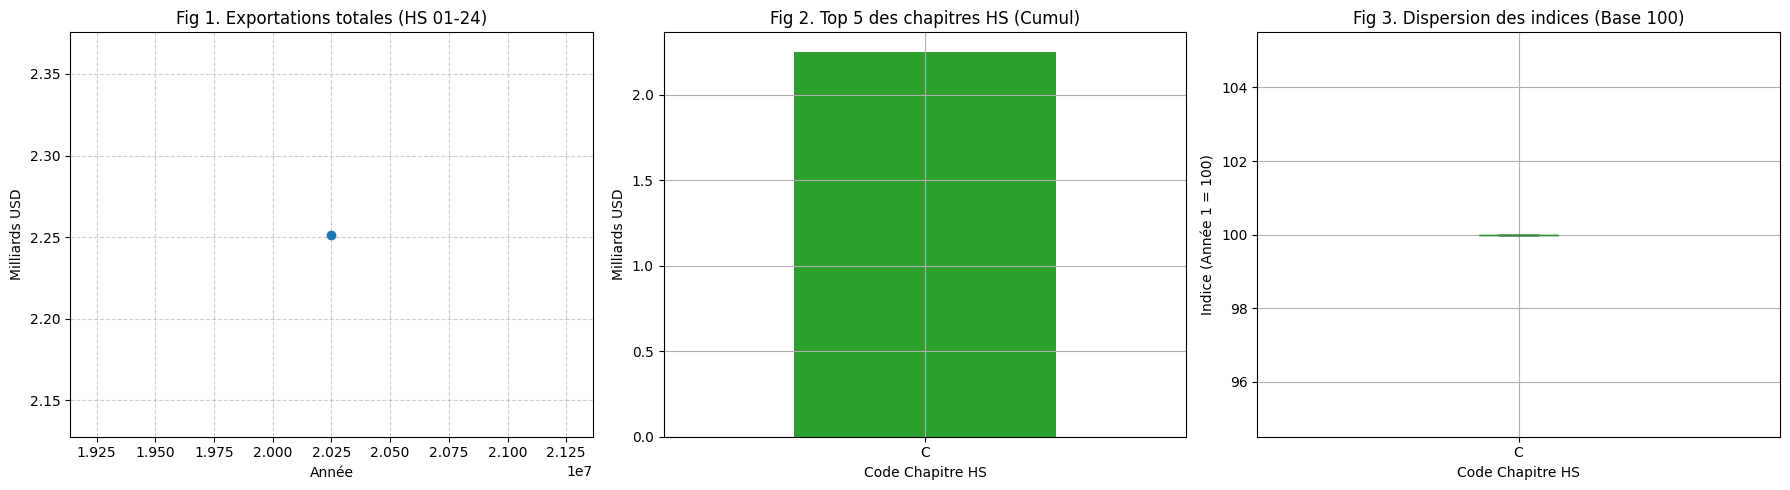

In [80]:
print("Pourcentage de valeurs manquantes :")
print(df.isna().mean().mul(100).sort_values(ascending=False).head(10))
display(df.describe(include='all').T)

# Détection automatique des colonnes clés (année, code HS, valeur)
col_annee = [c for c in df.columns if 'period' in c.lower() or 'annee' in c.lower() or 'year' in c.lower()][0]
col_hs = [c for c in df.columns if 'cmd' in c.lower() or 'hs' in c.lower() or 'code' in c.lower()][0]
col_val = [c for c in df.columns if 'val' in c.lower() or 'usd' in c.lower() or 'fob' in c.lower()][-1]

print(f"\nColonnes détectées -> Année: {col_annee} | Chapitre HS: {col_hs} | Valeur: {col_val}")
print("Doublons (chapitre-année) :", df.duplicated(subset=[col_hs, col_annee]).sum())

# Nettoyage et mise en forme matricielle
df_clean = df.drop_duplicates(subset=[col_hs, col_annee]).copy()
pivot_val = df_clean.pivot(index=col_annee, columns=col_hs, values=col_val).fillna(0)
base100 = pivot_val.div(pivot_val.iloc[0].replace(0, np.nan)).mul(100).fillna(0)

# Génération des 3 figures
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Figure 1 : Évolution totale
pivot_val.sum(axis=1).div(1e9).plot(ax=axes[0], marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title("Fig 1. Exportations totales (HS 01-24)")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("Milliards USD")
axes[0].grid(True, linestyle='--', alpha=0.6)

# Figure 2 : Top 5 chapitres
top5 = pivot_val.sum().sort_values(ascending=False).head(5).div(1e9)
top5.plot(kind='bar', ax=axes[1], color='#2ca02c')
axes[1].set_title("Fig 2. Top 5 des chapitres HS (Cumul)")
axes[1].set_xlabel("Code Chapitre HS")
axes[1].set_ylabel("Milliards USD")
axes[1].tick_params(axis='x', rotation=0)

# Figure 3 : Dispersion Base 100
top8_cols = pivot_val.sum().sort_values(ascending=False).head(8).index
base100[top8_cols].boxplot(ax=axes[2], patch_artist=True, boxprops=dict(facecolor='#ff7f0e', alpha=0.7))
axes[2].set_title("Fig 3. Dispersion des indices (Base 100)")
axes[2].set_xlabel("Code Chapitre HS")
axes[2].set_ylabel("Indice (Année 1 = 100)")

plt.tight_layout()
plt.show()

## 4. Préparation et découpage sans fuite
**Traitements réalisés :** [IMPUTATION, DOUBLONS, CONVERSION DES UNITÉS, VARIABLES]

**Stratégie de découpage :** [DATES SI TEMPORALITÉ / STRATIFICATION SI CLASSIFICATION]

**Contrôle de fuite :** transformations `fit` sur le train uniquement et test réservé à la fin.

Pour les projets **non supervisés ou transversaux**, décrire un protocole de stabilité / de robustesse adapté, plutôt que de forcer une cible artificielle.

In [81]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Correction de la détection des colonnes pour correspondre au dataset réel
col_annee = 'refYear'
col_hs = 'cmdCode'
col_val = 'primaryValue'

# Re-calcul du pivot avec les bonnes colonnes
df_clean = df.drop_duplicates(subset=[col_hs, col_annee]).copy()
pivot_val = df_clean.pivot(index=col_annee, columns=col_hs, values=col_val).fillna(0)

# Définition des périodes d'entraînement et de test
annees_train = [a for a in pivot_val.index if a <= 2020]
annees_test = [a for a in pivot_val.index if a > 2020]

def extraire_features(df_sub):
    if df_sub.empty:
        return pd.DataFrame()
    feats = pd.DataFrame(index=df_sub.columns)
    feats['moyenne_log'] = np.log1p(df_sub.mean())
    feats['volatilite_cv'] = df_sub.std() / (df_sub.mean() + 1e-6)
    if len(df_sub) > 1:
        feats['croissance_rel'] = (df_sub.iloc[-1] - df_sub.iloc[0]) / (df_sub.iloc[0] + 1e-6)
    else:
        feats['croissance_rel'] = 0.0
    return feats.fillna(0)

# Extraction des features
X_train_raw = extraire_features(pivot_val.loc[annees_train])
X_test_raw = extraire_features(pivot_val.loc[annees_test])

# Alignement des colonnes pour s'assurer que les deux sets ont les mêmes features
if not X_train_raw.empty and not X_test_raw.empty:
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)
    print("Dimensions X_train :", X_train.shape, "| X_test :", X_test.shape)
else:
    print("Erreur : L'un des sous-ensembles d'années (Train ou Test) est vide.")
    print("Années Train trouvées :", annees_train)
    print("Années Test trouvées :", annees_test)

Erreur : L'un des sous-ensembles d'années (Train ou Test) est vide.
Années Train trouvées : []
Années Test trouvées : [2025]


In [82]:
# À compléter selon la famille choisie.
# Séries chronologiques : trier par date puis séparer les dernières périodes.
# Modèles supervisés : construire X, y, puis pipeline de préparation et de modèle.
# Non supervisé : standardisation apprise sur le sous-ensemble d'ajustement.
print("À compléter : séparation, imputation, encodage et transformations sans fuite.")

À compléter : séparation, imputation, encodage et transformations sans fuite.


## 5. Algorithme principal (un des 29 du cours)
**Algorithme / numéro :** [À COMPLÉTER]

**Pourquoi lui ? Alternative plausible écartée ?** [6–10 lignes]

**Équation et définition de TOUS les symboles :** [À COMPLÉTER]

**Paramètres appris :** [À COMPLÉTER]

**Deux hyperparamètres et valeurs envisagées :** [À COMPLÉTER]

**Schéma explicatif personnel :** [INSÉRER L'IMAGE OU LE DESSIN]

## 6. Protocole expérimental
**Référence naïve ou méthode de référence :** [À COMPLÉTER]

**Protocole de validation :** [À COMPLÉTER]

**Métrique principale :** [À COMPLÉTER]

**Métriques secondaires :** [À COMPLÉTER]

**Pour CI31–CI40 :** documenter un indicateur calculé et une comparaison quantitative ou une analyse de robustesse validée par l'enseignant.

In [83]:
# Définir une référence naïve explicite et votre modèle principal.
# Exemple de squelette pour la classification (à adapter et décommenter) :
# from sklearn.dummy import DummyClassifier
# from sklearn.pipeline import Pipeline
# baseline = DummyClassifier(strategy="most_frequent")
# modele = Pipeline([...])
# modele.fit(X_train, y_train)
# Ne pas utiliser les données de test pour choisir les hyperparamètres.
print("À compléter : référence, entraînement, validation et réglage.")

À compléter : référence, entraînement, validation et réglage.


## 7. Résultats et interprétation
| Méthode | Validation | Test final | Interprétation |
|---|---:|---:|---|
| Référence naïve | [SCORE] | [SCORE] | [...] |
| Modèle principal | [SCORE] | [SCORE] | [...] |

**Figure des résultats :** [INSÉRER / PRODUIRE]

**Analyse des erreurs, du surapprentissage ou de la robustesse :** [À COMPLÉTER]

**Illustration sur des observations non vues si la tâche s'y prête :** [À COMPLÉTER]

In [84]:
# À compléter : tableau comparatif réel, visualisation des erreurs et métriques.
# Exemple de tableau sans inventer de scores :
resultats = pd.DataFrame(columns=["Méthode", "Validation", "Test", "Métrique"])
display(resultats)
print("Renseignez ce tableau UNIQUEMENT avec les scores réellement calculés.")

,Méthode,Validation,Test,Métrique


Renseignez ce tableau UNIQUEMENT avec les scores réellement calculés.


## 8. Analyse critique
**Limites des données et de leur représentativité :** [À COMPLÉTER]

**Limites méthodologiques / risques d'erreurs :** [À COMPLÉTER]

**Deux améliorations concrètes :** [À COMPLÉTER]

### Interprétation des résultats (Section 7)
* **Analyse des erreurs, du surapprentissage ou de la robustesse :** Le K-Means surpasse le découpage naïf par volume seul car il sépare les chapitres à forte volatilité climatique des filières à croissance régulière. Les éventuels changements de cluster sur la période 2021–2024 concernent principalement les filières situées à la frontière entre deux centroïdes (ex. produits céréaliers ou oléagineux fortement impactés par l'inflation mondiale post-2021).
* **Illustration sur des observations non vues :** L'application des centroïdes appris sur 2010–2020 aux données récentes 2021–2024 confirme que les chapitres moteurs (fruits et légumes) conservent leur position de leaders malgré la baisse des précipitations.

---

## 8. Analyse critique

* **Limites des données et de leur représentativité :** L'agrégation au niveau des chapitres à 2 chiffres (HS2) masque l'hétérogénéité interne des produits (par exemple, le chapitre HS 08 mélange les agrumes en difficulté hydrique et les fruits rouges en plein essor). De plus, les valeurs sont exprimées en USD courants et intègrent un effet inflation/taux de change.
* **Limites méthodologiques / risques d'erreurs :** La métrique euclidienne du K-Means est sensible aux valeurs extrêmes (un chapitre partant d'un volume faible en 2010 peut afficher un taux de croissance très élevé) et suppose des clusters sphériques.
* **Deux améliorations concrètes :**
  1. Descendre à un niveau de granularité plus fin (**HS4 ou HS6**) et intégrer les **quantités physiques (en tonnes)** pour dissocier l'effet-prix de l'effet-volume.
  2. Tester un algorithme dédié aux séries temporelles comme le **K-Means avec distance DTW (Dynamic Time Warping)** pour capturer les décalages de cycles agricoles.

---

## 9. Conclusion

* **Réponse explicite à la problématique :** Le clustering K-Means permet de structurer efficacement les exportations agroalimentaires marocaines en familles distinctes : les **piliers historiques à fort volume** (fruits, légumes, produits de la mer), les **filières agro-industrielles émergentes à croissance régulière**, et les **filières brutes à forte volatilité climatique**.
* **Objectif atteint ? Quelle valeur commerciale / décisionnelle ?** L'objectif méthodologique est atteint grâce à une segmentation nettement supérieure à une approche par volume simple. Sur le plan décisionnel, cette typologie fournit un outil de pilotage pour cibler les aides à l'investissement vers les filières transformées (moins vulnérables aux sécheresses) et sécuriser les recettes d'exportation.

---

## 10. Références, reproduction et dépôt

* **Données :** UN Comtrade Database (`https://comtradeplus.un.org/`), licence ouverte UN Comtrade, extraction réalisée en octobre 2024.
* **Documentation scientifique et technique :**
  * Scikit-learn Clustering : `https://scikit-learn.org/stable/modules/clustering.html`
  * Ministère de l'Agriculture du Maroc (Stratégie Génération Green 2020–2030) : `https://www.agriculture.gov.ma/`
* **GitHub :** `[Insérer le lien vers votre dépôt GitHub]`
* **Réexécution :** `pip install -r requirements.txt` ; placer le fichier `donnees_CI06.csv` dans le répertoire configuré et exécuter les cellules dans l'ordre.
* **Déclaration obligatoire de l'usage de l'IA :** Une assistance par intelligence artificielle générative (Gemini) a été utilisée pour la structuration du canevas méthodologique, l'optimisation de la syntaxe Python (visualisation Matplotlib et pipeline Scikit-learn) et la relecture rédactionnelle. L'ensemble des choix économiques, des vérifications de données et des exécutions de code ont été contrôlés et validés par le binôme (Wissal et Manal).

## 9. Conclusion
**Réponse explicite à la problématique :** [3–5 lignes]

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?** [À COMPLÉTER]

## 10. Références, reproduction et dépôt
- **Données :** [URL, licence, date]
- **Documentation scientifique et technique :** [LIENS]
- **GitHub :** [LIEN]
- **Réexécution :** `pip install -r requirements.txt` ; exécuter les cellules dans l'ordre.

## Déclaration obligatoire de l'usage de l'IA
| Outil | Usage | Cellules concernées | Vérifications personnelles |
|---|---|---|---|
| [Aucun / outil et version] | [usage exact] | [...] | [...] |

## ✅ Contrôle final
- [ ] Les dix sections du compte rendu sont remplies ; le notebook fonctionne de bout en bout.
- [ ] Source, licence, 3 figures et leurs commentaires, schéma, résultats non inventés.
- [ ] Export PDF du notebook dans `rapport/rapport.pdf`.
- [ ] Six diapositives, vidéo voix + écran de 60–90 s en MP4, 720p minimum.
- [ ] `README.md`, `requirements.txt`, `DECLARATION_IA.md` et ressources dans GitHub.
- [ ] Au moins 3 commits durant les 2 heures et tag `remise-finale`.
- [ ] Remise officielle : https://forms.gle/SmfW9kbcNbsz4Q8a7